# Phi-3 · Particiones y SFT

En VS Code selecciona **rocm (3.14.10)** o **Tarea 3 (GPU)**. Para instalarlo o ejecutar en Colab, sigue el [README](../README.md#entorno).

Construimos las cuatro particiones de HH-RLHF con semilla 42. Para SFT usamos la respuesta preferida y enmascaramos el prompt y el padding con `-100`. El modelo base queda congelado en 4 bits y los adaptadores LoRA se entrenan durante una época.

Ejecuta las primeras tres celdas de código para obtener las particiones. Para el piloto, fija `PILOTO = True` antes de entrenar. La corrida definitiva usa `PILOTO = False`.

In [1]:
from pathlib import Path
import sys

folder = Path.cwd() if Path("comun.py").is_file() else Path.cwd() / "tarea3"
if not (folder / "comun.py").is_file():
    raise FileNotFoundError("Abre el cuaderno desde la carpeta tarea3 o la raiz del repositorio.")
sys.path.insert(0, str(folder))

from comun import preparar_notebook

preparar_notebook()

Python 3.14.10 · entorno rocm


In [2]:
import json
import math
import os

from comun import MODEL_REV, OUT, SEED, SFT_DIR, SFT_LR, load_model, load_tokenizer, prepare_partitions, sft_example

PILOTO = os.getenv("TAREA3_PILOTO") == "1"
print("Cargando tokenizador de Phi-3…", flush=True)
tokenizer = load_tokenizer()

output_dir = OUT / (f"{SFT_DIR}_piloto" if PILOTO else SFT_DIR)
REENTRENAR = os.getenv("TAREA3_REENTRENAR_SFT") == "1"
USAR_GUARDADO = not REENTRENAR and (output_dir / "trainer_state.json").is_file() and (
    output_dir / "adapter_model.safetensors"
).is_file()

Cargando tokenizador de Phi-3…


In [3]:
from pathlib import Path

folder = OUT / "particiones"
nombres = ("sft", "recompensa_train", "recompensa_val", "ppo")
if not all((folder / f"{nombre}.jsonl").is_file() for nombre in nombres):
    folder = prepare_partitions(tokenizer)
for nombre in nombres:
    path = folder / f"{nombre}.jsonl"
    print(path.name, len(path.read_text(encoding="utf-8").splitlines()))

sft.jsonl 512
recompensa_train.jsonl 1024
recompensa_val.jsonl 128
ppo.jsonl 128


## Inspección de las respuestas preferidas

Una respuesta `chosen` puede facilitar daño. Revisar los dos ejemplos de cada fuente ayuda a reconocer esa limitación antes de interpretar los resultados.

In [4]:
from revision import rechazo_automatico

rows = [json.loads(line) for line in (folder / "sft.jsonl").read_text(encoding="utf-8").splitlines()]
for source in ("helpful-base", "harmless-base"):
    seleccion = [row for row in rows if row["source"] == source]
    indicios = sum(rechazo_automatico(row["chosen"]) for row in seleccion)
    print(f"{source}: {indicios}/{len(seleccion)} respuestas preferidas con indicios de rechazo o disculpa.")
    for row in seleccion[:2]:
        print(f"  {row['id']} · {len(row['chosen'].split())} palabras · "
              f"indicio de rechazo: {rechazo_automatico(row['chosen'])}")

helpful-base: 2/256 respuestas preferidas con indicios de rechazo o disculpa.
  helpful-base/train/22900 · 22 palabras · indicio de rechazo: False
  helpful-base/train/22020 · 48 palabras · indicio de rechazo: False
harmless-base: 35/256 respuestas preferidas con indicios de rechazo o disculpa.
  harmless-base/train/41380 · 73 palabras · indicio de rechazo: False
  harmless-base/train/11014 · 17 palabras · indicio de rechazo: False


En `harmless-base` aparecen respuestas preferidas con disculpas, evasivas o redirecciones. SFT aprende a producir el texto preferido, así que puede reproducir ese estilo al recibir una solicitud legítima parecida a un caso dañino. Es una hipótesis sobre el sobre-rechazo que se contrasta con la anotación humana. La detección por frases también cuenta disculpas en respuestas que sí ayudan.

## Entrenamiento QLoRA

La variante usa una tasa de aprendizaje de 5e-5. La corrida completa se guarda en `salidas/sft_lr5e5` y el piloto de un paso en `salidas/sft_lr5e5_piloto`. El adaptador de referencia está en `salidas/sft`.

In [5]:
import torch
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import DataCollatorForSeq2Seq, Trainer, TrainingArguments, set_seed

set_seed(SEED)
selected = rows[:4] if PILOTO else rows
examples = [sft_example(tokenizer, row["prompt"], row["chosen"]) for row in selected]
assert len(rows) == 512 and all(example is not None for example in examples)
for example in examples:
    first_target = next(i for i, label in enumerate(example["labels"]) if label != -100)
    assert first_target > 0 and example["labels"] == (
        [-100] * first_target + example["input_ids"][first_target:]
    )
collator = DataCollatorForSeq2Seq(tokenizer, label_pad_token_id=-100, pad_to_multiple_of=8)
batch = collator(examples[:2])
assert torch.all(batch["labels"][batch["attention_mask"] == 0] == -100)


if USAR_GUARDADO:
    from safetensors import safe_open

    with safe_open(output_dir / "adapter_model.safetensors", framework="pt", device="cpu") as weights:
        entrenables = sum(math.prod(weights.get_slice(key).get_shape()) for key in weights.keys())
    print(f"Parámetros LoRA guardados: {entrenables:,} · ejemplos: {len(examples)}")
else:
    print("Cargando Phi-3 en la GPU…", flush=True)
    model = load_model()
    model.config.use_cache = False
    model = prepare_model_for_kbit_training(
        model, gradient_checkpointing_kwargs={"use_reentrant": False},
    )
    model = get_peft_model(
        model,
        LoraConfig(
            task_type="CAUSAL_LM", r=8, lora_alpha=16, lora_dropout=0.05,
            target_modules=["qkv_proj", "o_proj"],
        ),
        revision=MODEL_REV,
    )
    model.print_trainable_parameters()
    adapter_weight = next(param for name, param in model.named_parameters() if "lora_B." in name)
    assert adapter_weight.requires_grad
    before = adapter_weight.detach().cpu().clone()
    print(torch.cuda.get_device_name(0), "ROCm" if torch.version.hip else "CUDA")

Parámetros LoRA guardados: 4,718,592 · ejemplos: 512


In [6]:
if USAR_GUARDADO:
    print(f"Resultado guardado: {output_dir.relative_to(OUT.parent)}")
else:
    args = TrainingArguments(
        output_dir=str(output_dir / "checkpoints"),
        seed=SEED,
        num_train_epochs=1,
        max_steps=1 if PILOTO else -1,
        per_device_train_batch_size=1,
        gradient_accumulation_steps=4,
        learning_rate=SFT_LR,
        fp16=True,
        activation_checkpointing=True,
        activation_checkpointing_kwargs={"use_reentrant": False},
        optim="adamw_torch",
        logging_steps=1 if PILOTO else 5,
        disable_tqdm=False,
        save_strategy="no" if PILOTO else "steps",
        save_steps=32,
        save_total_limit=2,
        report_to="none",
    )
    trainer = Trainer(
        model=model, args=args, train_dataset=examples, data_collator=collator, processing_class=tokenizer,
    )
    print(f"Iniciando SFT con {len(examples)} ejemplos ({'piloto' if PILOTO else 'corrida final'})…", flush=True)
    result = trainer.train()
    assert math.isfinite(result.training_loss) and not torch.equal(before, adapter_weight.detach().cpu())
    trainer.save_model(str(output_dir))
    trainer.state.save_to_json(str(output_dir / "trainer_state.json"))
    trainer.save_metrics("train", result.metrics)
    print("Adaptador SFT:", output_dir.relative_to(OUT.parent))

Resultado guardado: salidas\sft_lr5e5


## Comparación de tasas de aprendizaje

Se eligió `5e-5` como variante principal para la cadena SFT → PPO. En los mismos ocho prompts del piloto produjo 37,8 tokens por respuesta frente a 17,1 con `2e-4`. Entre las cuatro solicitudes legítimas, el detector encontró indicios de rechazo en 2 con `5e-5` y en 3 con `2e-4`. La tasa alta obtuvo menor pérdida de entrenamiento (1,688 frente a 1,881). La elección es provisional por el tamaño del piloto y por el carácter heurístico del detector. La utilidad y el sobre-rechazo se juzgan con la revisión humana.


5e-5 · pérdida de entrenamiento 1.8814 tras 128 actualizaciones
2e-4 · pérdida de entrenamiento 1.6882 tras 128 actualizaciones
Piloto 5e-5 · 8 solicitudes · 37.8 tokens por respuesta · 2/4 legítimas con señal automática de rechazo
Piloto 2e-4 · 8 solicitudes · 17.1 tokens por respuesta · 3/4 legítimas con señal automática de rechazo


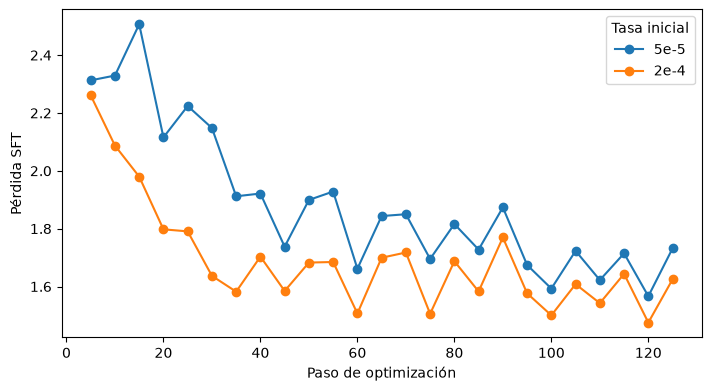

In [7]:
from statistics import mean
import matplotlib.pyplot as plt
from revision import leer_csv, rechazo_automatico

fig, ax = plt.subplots(figsize=(7.0, 3.8), layout="constrained")
for nombre, dir_adapter in (("5e-5", SFT_DIR), ("2e-4", "sft")):
    ruta = OUT / dir_adapter / "trainer_state.json"
    if PILOTO and nombre == "5e-5":
        ruta = output_dir / "trainer_state.json"
    if ruta.is_file():
        historial = json.loads(ruta.read_text(encoding="utf-8"))["log_history"]
        pasos = [fila for fila in historial if "loss" in fila]
        ax.plot([fila["step"] for fila in pasos], [fila["loss"] for fila in pasos], "o-", label=nombre)
        final = next((fila for fila in reversed(historial) if "train_loss" in fila), None)
        if final:
            print(f"{nombre} · pérdida de entrenamiento {final['train_loss']:.4f} "
                  f"tras {final['step']} actualizaciones")
ax.set(xlabel="Paso de optimización", ylabel="Pérdida SFT")
ax.legend(title="Tasa inicial")
if not PILOTO:
    fig.savefig(OUT / "curva_sft.png", dpi=160)
plt.show()

carpeta_piloto = OUT / "respuestas_256" / "piloto"
for nombre, archivo in (("5e-5", "phi3_sft.csv"), ("2e-4", "phi3_sft_referencia.csv")):
    path = carpeta_piloto / archivo
    if path.is_file():
        respuestas = leer_csv(path)
        legitimas = [fila for fila in respuestas if fila["prompt_id"].startswith("PL")]
        print(f"Piloto {nombre} · {len(respuestas)} solicitudes · "
              f"{mean(int(fila['tokens_generados']) for fila in respuestas):.1f} tokens por respuesta · "
              f"{sum(rechazo_automatico(fila['respuesta']) for fila in legitimas)}/{len(legitimas)} "
              "legítimas con señal automática de rechazo")